<a href="https://colab.research.google.com/github/Alexanderpanu/rostelecom-pandas-numpy-labs/blob/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D1%8B%D0%B5-1.1%3B2-%3B%D0%9F%D0%B0%D0%BD%D1%8E%D0%BA%D0%BE%D0%B2-%D0%90%D0%BB%D0%B5%D0%BA%D1%81%D0%B0%D0%BD%D0%B4%D1%80-%3B%D0%98%D0%9F%D0%98%D0%A2-1520441-3-%D0%BA%D1%83%D1%80%D1%81/pandas_labs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

8.1 Исходных элементов: 10000, Уникальных координат: 9996, CSR nnz: 9996

8.2 Память Dense: 122.07 МБ | Память CSR: 0.93 МБ
8.2 Время (среднее из 100): Dense = 7.952 мс | CSR = 0.483 мс



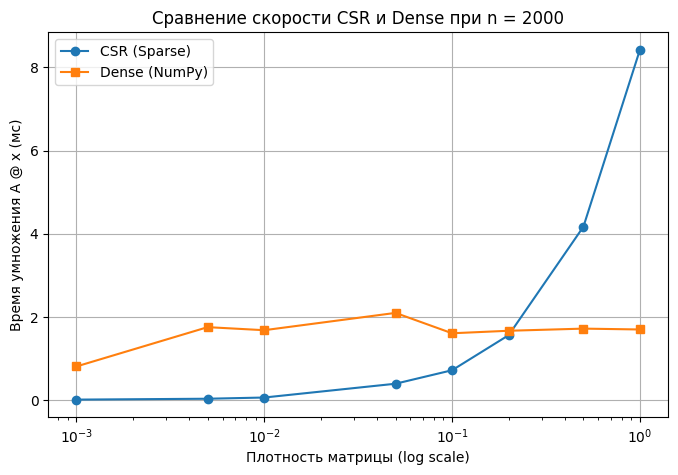

In [13]:
import scipy.sparse as sp
import matplotlib.pyplot as plt

np.random.seed(42)
row = np.random.randint(0, 5000, size=10000)
col = np.random.randint(0, 5000, size=10000)
data = np.random.rand(10000)

coo = sp.coo_matrix((data, (row, col)), shape=(5000, 5000))
csr = coo.tocsr()
unique_pairs = len(set(zip(row, col)))
print(f"8.1 Исходных элементов: 10000, Уникальных координат: {unique_pairs}, CSR nnz: {csr.nnz}\n")

sparse_mat = sp.random(4000, 4000, density=0.005, format='csr', dtype=np.float64)
dense_mat = sparse_mat.toarray()
vec = np.random.rand(4000)

dense_mem = dense_mat.nbytes / (1024**2)
sparse_mem = (sparse_mat.data.nbytes + sparse_mat.indices.nbytes + sparse_mat.indptr.nbytes) / (1024**2)
print(f"8.2 Память Dense: {dense_mem:.2f} МБ | Память CSR: {sparse_mem:.2f} МБ")

t0 = time.time()
for _ in range(100): _ = dense_mat @ vec
t_dense = (time.time() - t0) / 100

t0 = time.time()
for _ in range(100): _ = sparse_mat @ vec
t_sparse = (time.time() - t0) / 100
print(f"8.2 Время (среднее из 100): Dense = {t_dense*1000:.3f} мс | CSR = {t_sparse*1000:.3f} мс\n")

n = 2000
densities = [0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.5, 1.0]
x_vec = np.random.rand(n)
times_sparse = []
times_dense = []

for d in densities:
    S = sp.random(n, n, density=d, format='csr', dtype=np.float64)
    D = S.toarray()

    t0 = time.time()
    for _ in range(50): _ = S @ x_vec
    times_sparse.append((time.time() - t0) / 50 * 1000)

    t0 = time.time()
    for _ in range(50): _ = D @ x_vec
    times_dense.append((time.time() - t0) / 50 * 1000)

plt.figure(figsize=(8, 5))
plt.plot(densities, times_sparse, marker='o', label='CSR (Sparse)')
plt.plot(densities, times_dense, marker='s', label='Dense (NumPy)')
plt.xscale('log')
plt.xlabel('Плотность матрицы (log scale)')
plt.ylabel('Время умножения A @ x (мс)')
plt.title('Сравнение скорости CSR и Dense при n = 2000')
plt.legend()
plt.grid(True)
plt.show()
